# Resize, translation, rotate, and flip


In [1]:
from pathlib import Path

# Locate the img folder beside 01_start from common Jupyter working directories.
image_dirs = (Path.cwd() / '../img', Path.cwd() / 'img', Path.cwd() / '07_opencv/img')
img_dir = next((p.resolve() for p in image_dirs if (p / 'img1.jpg').is_file() and (p / 'img2.jpg').is_file()), None)
if img_dir is None:
    raise FileNotFoundError('Cannot locate 07_opencv/img. Run from the workspace, 07_opencv, or 01_start directory.')

import cv2
import numpy as np
import matplotlib.pyplot as plt

img_path = str(img_dir / 'img1.jpg')
img = cv2.imread(img_path, cv2.IMREAD_COLOR)
if img is None:
    raise FileNotFoundError(f'Cannot read image: {img_path}')
print(f'Image shape: {img.shape}, dtype: {img.dtype}')


Image shape: (3648, 5472, 3), dtype: uint8


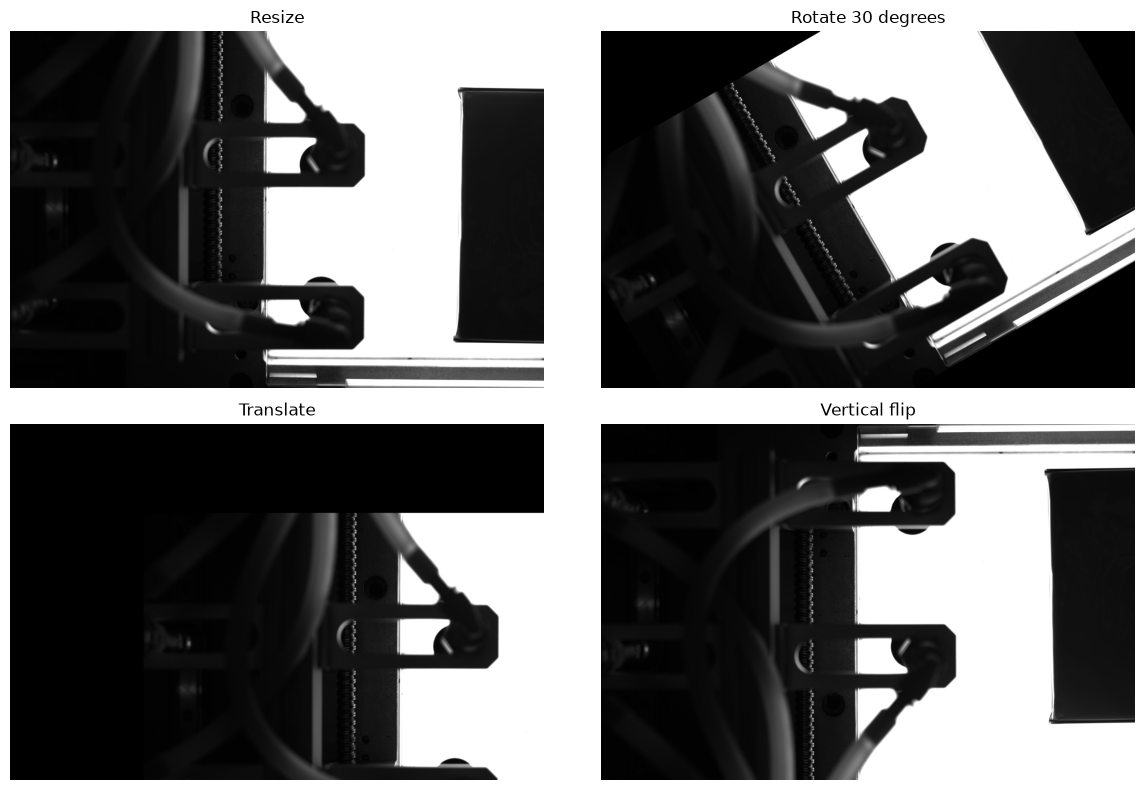

In [2]:
height, width = img.shape[:2]
resized_img = cv2.resize(img, (max(1, width // 2), max(1, height // 2)))

center = (width / 2, height / 2)
rotation_matrix = cv2.getRotationMatrix2D(center, 30, 1.0)
rotated_img = cv2.warpAffine(img, rotation_matrix, (width, height))

translation_matrix = np.float32([[1, 0, width // 4], [0, 1, height // 4]])
translated_img = cv2.warpAffine(img, translation_matrix, (width, height))

flipped_img = cv2.flip(img, 0)  # 0: vertical, 1: horizontal, -1: both axes

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
items = [
    ('Resize', resized_img),
    ('Rotate 30 degrees', rotated_img),
    ('Translate', translated_img),
    ('Vertical flip', flipped_img),
]
for axis, (title, image) in zip(axes.flat, items):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()
